In [1]:
# ============================================================
# 1. Imports
# ============================================================

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance

import joblib

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)


In [2]:
excel_path = Path("osmos_simulation_data.xlsx")

if not excel_path.exists():
    raise FileNotFoundError("Put osmos_simulation_data.xlsx in the same folder as this notebook.")

snapshots = pd.read_excel(excel_path, sheet_name="Digital_Twins")
profiles = pd.read_excel(excel_path, sheet_name="Customers")
events = pd.read_excel(excel_path, sheet_name="Events_Sample")
rules = pd.read_excel(excel_path, sheet_name="Action_Rules")

print("Snapshots:", snapshots.shape)
print("Profiles:", profiles.shape)
print("Events:", events.shape)
print("Rules:", rules.shape)

snapshots[[
    "entity_id",
    # "entity_type",
    # "recency_days",
    # "purchases_90d",
    # "total_spent_90d_mad",
    # "rfm_recency_score",
    # "rfm_frequency_score",
    # "rfm_monetary_score",
    "rfm_score"
]].head()


Snapshots: (1500, 25)
Profiles: (1500, 14)
Events: (5000, 12)
Rules: (9, 5)


,entity_id,rfm_score
0,P00001,0.000
1,C00002,0.542
2,C00003,0.759
3,P00004,0.000
4,C00005,0.411


Classes disponibles:
dynamic_class
Warm Prospect        392
Hot Prospect         234
Active Client        225
Cold Prospect        193
Loyal Client         190
VIP Client           128
Churn Risk Client    121
New Client             9
Dormant Client         8
Name: count, dtype: int64


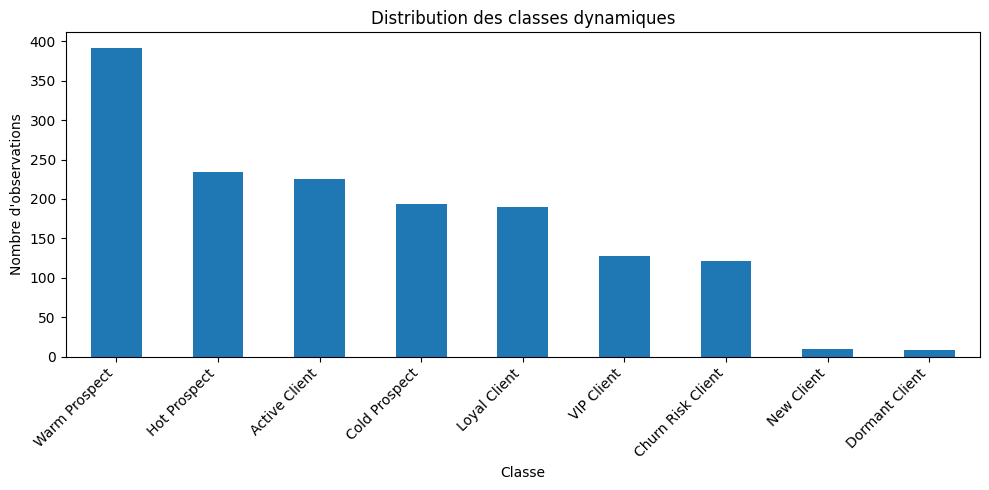

In [3]:
# ============================================================
# 3. Target distribution
# ============================================================

TARGET = "dynamic_class"

print("Classes disponibles:")
print(snapshots[TARGET].value_counts())

plt.figure(figsize=(10, 5))
snapshots[TARGET].value_counts().plot(kind="bar")
plt.title("Distribution des classes dynamiques")
plt.xlabel("Classe")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [4]:
# ============================================================
# 4. Merge snapshots + profiles
# ============================================================

df = snapshots.merge(
    profiles,
    on=["entity_id", "entity_type"],
    how="left",
    suffixes=("", "_profile")
)

print("Merged dataset:", df.shape)
df.head()

Merged dataset: (1500, 37)


,entity_id,entity_type,snapshot_date,basic_profile_score,behavioral_engagement_score,predictive_value_score,decision_priority_score,recency_days,visits_30d,product_views_30d,cart_additions_30d,purchases_90d,total_spent_90d_mad,avg_order_value_mad,email_open_rate,email_click_rate,complaint_count_90d,review_score_avg,social_mentions_30d,social_sentiment_avg,rfm_score,conversion_probability,churn_risk_score,dynamic_class,recommended_action,created_at,region,source_channel,segment,persona,age_group,preferred_device,preferred_category,marketing_consent,price_sensitivity,income_power_score,initial_interest_score
0,P00001,Prospect,2026-06-17,0.458,0.135,0.156,0.131,27,3,12,0,0,0.00,0.00,0.378,0.059,0,NaN,0,0.367,0.000,0.119,0.000,Cold Prospect,Continue awareness campaign,2025-09-12,Fès-Meknès,Facebook Ads,Student,Price Sensitive,18-24,Desktop,Electronics,True,0.957,0.285,0.135
1,C00002,Client,2026-06-17,0.734,0.204,0.400,0.359,30,1,3,0,3,2974.47,991.49,0.328,0.039,1,2.78,1,0.505,0.542,1.000,0.396,Active Client,Send personalized product recommendation,2025-10-20,Laâyoune-Sakia El Hamra,Google Search,Student,B2B Decision Maker,35-44,Desktop,Fashion,True,0.367,0.736,0.115
2,C00003,Client,2026-06-17,0.440,0.607,0.638,0.345,12,17,74,13,6,3733.08,622.18,0.478,0.114,0,3.97,2,0.782,0.759,1.000,0.000,VIP Client,Send VIP loyalty reward,2026-05-14,Rabat-Salé-Kénitra,Marketplace App,B2C,Quality Seeker,35-44,Mobile,Home,True,0.792,0.138,0.613
3,P00004,Prospect,2026-06-17,0.525,1.000,0.726,0.808,21,26,96,12,0,0.00,0.00,0.352,0.054,0,NaN,3,0.820,0.000,0.794,0.000,Hot Prospect,Send limited-time personalized offer,2025-09-02,Marrakech-Safi,Organic SEO,Family,Trend Follower,18-24,Desktop,Fashion,True,0.472,0.197,0.920
4,C00005,Client,2026-06-17,0.553,0.341,0.352,0.421,67,7,28,2,4,1747.41,436.85,0.517,0.091,0,4.24,2,0.053,0.411,1.000,0.510,Active Client,Send personalized product recommendation,2025-09-27,Casablanca-Settat,Referral,B2C,Quality Seeker,25-34,Mobile,Electronics,True,0.601,0.353,0.137


In [5]:
# ============================================================
# 4B. Recalculate RFM-ES using AHP Group Decision Making
#     3 expert matrices -> 1 aggregated final AHP matrix
# ============================================================

import numpy as np
import pandas as pd

# ============================================================
# 1. Drop old RFM/AHP columns if they already exist
# ============================================================

cols_to_drop_rfm = [
    "rfm_score",
    "rfm_score_raw_1_to_5",
    "R_raw",
    "F_raw",
    "M_raw",
    "E_raw",
    "S_raw",
    "rfm_recency_score",
    "rfm_frequency_score",
    "rfm_monetary_score",
    "rfm_engagement_score",
    "rfm_sentiment_score",
    "ahp_weight_R",
    "ahp_weight_F",
    "ahp_weight_M",
    "ahp_weight_E",
    "ahp_weight_S"
]

df = df.drop(columns=cols_to_drop_rfm, errors="ignore")

# ============================================================
# 2. Make sure needed columns exist
# ============================================================

needed_columns = {
    "entity_type": "Prospect",
    "recency_days": 0,
    "visits_30d": 0,
    "product_views_30d": 0,
    "cart_additions_30d": 0,
    "purchases_90d": 0,
    "total_spent_90d_mad": 0,
    "avg_order_value_mad": 0,
    "email_open_rate": 0,
    "email_click_rate": 0,
    "social_sentiment_avg": 0
}

for col, default_value in needed_columns.items():
    if col not in df.columns:
        df[col] = default_value

# ============================================================
# 3. Convert numeric columns
# ============================================================

numeric_cols_rfm = [
    "recency_days",
    "visits_30d",
    "product_views_30d",
    "cart_additions_30d",
    "purchases_90d",
    "total_spent_90d_mad",
    "avg_order_value_mad",
    "email_open_rate",
    "email_click_rate",
    "social_sentiment_avg"
]

for col in numeric_cols_rfm:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

# ============================================================
# 4. Detect clients/prospects safely
# Works if entity_type is string: "Client" / "Prospect"
# Works also if encoded: Client = 1, Prospect = 0
# ============================================================

is_client = (
    df["entity_type"].astype(str).str.lower().isin(["client", "1"])
)

# ============================================================
# 5. Safe quintile scoring function
# Output: score from 1 to 5
# 5 = best behavior
# ============================================================

def quintile_score(series, reverse=False):
    series = pd.to_numeric(series, errors="coerce").fillna(0)

    if series.nunique() <= 1:
        score = pd.Series(3, index=series.index)
    else:
        score = pd.qcut(
            series.rank(method="first"),
            q=5,
            labels=[1, 2, 3, 4, 5]
        ).astype(int)

    # For recency: lower recency_days is better
    if reverse:
        score = 6 - score

    return score

# ============================================================
# 6. Raw RFM-ES components
# ============================================================

# R: Recency
# Lower recency_days = better
df["R_raw"] = df["recency_days"]

# F: Frequency
# Clients: purchases_90d
# Prospects: interaction frequency
df["F_raw"] = np.where(
    is_client,
    df["purchases_90d"],
    df["visits_30d"] + df["product_views_30d"] + df["cart_additions_30d"]
)

# M: Monetary
# Clients: average order value
# Prospects: 0
df["M_raw"] = np.where(
    is_client,
    df["avg_order_value_mad"],
    0
)

# If avg_order_value_mad is missing or equal to 0,
# calculate it from total_spent_90d_mad / purchases_90d
mask_client_with_missing_aov = (
    is_client &
    (df["avg_order_value_mad"] == 0) &
    (df["purchases_90d"] > 0)
)

df.loc[mask_client_with_missing_aov, "M_raw"] = (
    df.loc[mask_client_with_missing_aov, "total_spent_90d_mad"] /
    df.loc[mask_client_with_missing_aov, "purchases_90d"]
)

# E: Engagement
# Based on clicks, opens, and product views
max_product_views = df["product_views_30d"].max()

if max_product_views == 0:
    normalized_product_views = pd.Series(0, index=df.index)
else:
    normalized_product_views = df["product_views_30d"] / max_product_views

df["E_raw"] = (
    0.40 * df["email_click_rate"] +
    0.30 * df["email_open_rate"] +
    0.30 * normalized_product_views
)

# S: Sentiment
# If sentiment is in [-1, 1], convert it to [0, 1]
# If it is already in [0, 1], keep it
if df["social_sentiment_avg"].min() < 0:
    df["S_raw"] = (df["social_sentiment_avg"] + 1) / 2
else:
    df["S_raw"] = df["social_sentiment_avg"]

df["S_raw"] = df["S_raw"].clip(0, 1)

# ============================================================
# 7. Convert RFM-ES components into scores from 1 to 5
# ============================================================

df["rfm_recency_score"] = quintile_score(df["R_raw"], reverse=True)
df["rfm_frequency_score"] = quintile_score(df["F_raw"])
df["rfm_monetary_score"] = quintile_score(df["M_raw"])
df["rfm_engagement_score"] = quintile_score(df["E_raw"])
df["rfm_sentiment_score"] = quintile_score(df["S_raw"])

# ============================================================
# 8. AHP helper functions
# ============================================================

def calculate_ahp_weights(pairwise_matrix, criteria):
    """
    Calculate AHP weights using the eigenvector method.
    Also calculates Consistency Index CI and Consistency Ratio CR.
    """

    pairwise_matrix = np.array(pairwise_matrix, dtype=float)
    n = pairwise_matrix.shape[0]

    eigenvalues, eigenvectors = np.linalg.eig(pairwise_matrix)

    max_index = np.argmax(eigenvalues.real)
    max_eigenvalue = float(eigenvalues.real[max_index])

    # Principal eigenvector must be positive.
    principal_eigenvector = np.abs(eigenvectors[:, max_index].real)
    weights = principal_eigenvector / principal_eigenvector.sum()

    # Consistency Index
    CI = (max_eigenvalue - n) / (n - 1)

    # Random Index values used in AHP
    RI_dict = {
        1: 0.00,
        2: 0.00,
        3: 0.58,
        4: 0.90,
        5: 1.12,
        6: 1.24,
        7: 1.32,
        8: 1.41,
        9: 1.45,
        10: 1.49
    }

    RI = RI_dict.get(n, 1.49)
    CR = 0 if RI == 0 else CI / RI

    weights_dict = {
        criteria[i]: float(weights[i])
        for i in range(n)
    }

    return weights_dict, float(CI), float(CR), max_eigenvalue


def aggregate_expert_matrices_geometric_mean(expert_matrices):
    """
    Group AHP aggregation:
    combines several expert pairwise matrices into one final matrix
    using the element-wise geometric mean.

    This is the standard aggregation of individual judgments.
    """

    matrices = np.array(expert_matrices, dtype=float)

    if np.any(matrices <= 0):
        raise ValueError("AHP matrices must contain strictly positive values.")

    aggregated_matrix = np.exp(np.mean(np.log(matrices), axis=0))

    # Numerical safety: force exact diagonal = 1 and reciprocal values.
    n = aggregated_matrix.shape[0]
    for i in range(n):
        aggregated_matrix[i, i] = 1.0
        for j in range(i + 1, n):
            aggregated_matrix[j, i] = 1.0 / aggregated_matrix[i, j]

    return aggregated_matrix


# ============================================================
# 9. Three expert AHP matrices for Clients: R, F, M, E, S
# ============================================================
# Criteria order:
# R = Recency
# F = Frequency
# M = Monetary
# E = Engagement
# S = Sentiment
#
# Expert 1: revenue-oriented view
# Expert 2: engagement-oriented view
# Expert 3: retention-oriented view
#
# The final matrix is obtained using the geometric mean of the 3 matrices.
# ============================================================

client_criteria = ["R", "F", "M", "E", "S"]

expert_1_matrix = [
    [1,   1,   1/3, 3,   2],
    [1,   1,   1/3, 2,   2],
    [3,   3,   1,   5,   4],
    [1/3, 1/2, 1/5, 1,   1],
    [1/2, 1/2, 1/4, 1,   1]
]

expert_2_matrix = [
    [1,   1,   1/2, 1/2, 1],
    [1,   1,   1/2, 1/2, 2],
    [2,   2,   1,   1,   3],
    [2,   2,   1,   1,   3],
    [1,   1/2, 1/3, 1/3, 1]
]

expert_3_matrix = [
    [1,   2,   1/2, 3,   1],
    [1/2, 1,   1/3, 2,   1/2],
    [2,   3,   1,   5,   2],
    [1/3, 1/2, 1/5, 1,   1/3],
    [1,   2,   1/2, 3,   1]
]

expert_matrices = {
    "Expert 1 - Revenue oriented": expert_1_matrix,
    "Expert 2 - Engagement oriented": expert_2_matrix,
    "Expert 3 - Retention oriented": expert_3_matrix
}

# Evaluate each expert matrix
expert_summaries = []

for expert_name, matrix in expert_matrices.items():
    weights, CI, CR, lambda_max = calculate_ahp_weights(matrix, client_criteria)

    expert_summaries.append({
        "expert": expert_name,
        "lambda_max": lambda_max,
        "CI": CI,
        "CR": CR,
        "consistent_CR_le_0_10": CR <= 0.10,
        "wR": weights["R"],
        "wF": weights["F"],
        "wM": weights["M"],
        "wE": weights["E"],
        "wS": weights["S"]
    })

expert_ahp_summary = pd.DataFrame(expert_summaries)

print("Individual expert AHP results:")
display(expert_ahp_summary)

# Aggregate the 3 expert matrices into one final group matrix
final_client_pairwise_matrix = aggregate_expert_matrices_geometric_mean(
    list(expert_matrices.values())
)

final_matrix_df = pd.DataFrame(
    final_client_pairwise_matrix,
    index=client_criteria,
    columns=client_criteria
)

print("\nFinal aggregated AHP matrix using geometric mean:")
display(final_matrix_df)

client_ahp_weights, client_CI, client_CR, client_lambda_max = calculate_ahp_weights(
    final_client_pairwise_matrix,
    client_criteria
)

client_ahp_weights_df = pd.DataFrame(
    list(client_ahp_weights.items()),
    columns=["criterion", "final_ahp_weight"]
)

print("\nFinal client AHP weights from aggregated matrix:")
display(client_ahp_weights_df)

print("Final Client lambda max:", round(client_lambda_max, 4))
print("Final Client CI:", round(client_CI, 4))
print("Final Client CR:", round(client_CR, 4))

if client_CR <= 0.10:
    print("Final aggregated AHP matrix is consistent: CR <= 0.10")
else:
    print("Warning: Final aggregated AHP matrix is not consistent: CR > 0.10")

# ============================================================
# 10. Prospect weights
# Prospects do not have Monetary value M.
# So we remove M and normalize R, F, E, S.
# ============================================================

prospect_ahp_weights = {
    "R": client_ahp_weights["R"],
    "F": client_ahp_weights["F"],
    "E": client_ahp_weights["E"],
    "S": client_ahp_weights["S"]
}

total_prospect_weight = sum(prospect_ahp_weights.values())

prospect_ahp_weights = {
    key: value / total_prospect_weight
    for key, value in prospect_ahp_weights.items()
}

prospect_ahp_weights_df = pd.DataFrame(
    list(prospect_ahp_weights.items()),
    columns=["criterion", "prospect_ahp_weight"]
)

print("\nProspect AHP weights after removing M and re-normalizing:")
display(prospect_ahp_weights_df)

# ============================================================
# 11. Final RFM-ES score using final group AHP weights
# ============================================================

client_score = (
    client_ahp_weights["R"] * df["rfm_recency_score"] +
    client_ahp_weights["F"] * df["rfm_frequency_score"] +
    client_ahp_weights["M"] * df["rfm_monetary_score"] +
    client_ahp_weights["E"] * df["rfm_engagement_score"] +
    client_ahp_weights["S"] * df["rfm_sentiment_score"]
)

prospect_score = (
    prospect_ahp_weights["R"] * df["rfm_recency_score"] +
    prospect_ahp_weights["F"] * df["rfm_frequency_score"] +
    prospect_ahp_weights["E"] * df["rfm_engagement_score"] +
    prospect_ahp_weights["S"] * df["rfm_sentiment_score"]
)

df["rfm_score_raw_1_to_5"] = np.where(
    is_client,
    client_score,
    prospect_score
)

# Normalize from [1, 5] to [0, 1]
df["rfm_score"] = (df["rfm_score_raw_1_to_5"] - 1) / 4
df["rfm_score"] = df["rfm_score"].clip(0, 1)

# ============================================================
# 12. Store final AHP weights for traceability
# ============================================================

df["ahp_weight_R"] = np.where(
    is_client,
    client_ahp_weights["R"],
    prospect_ahp_weights["R"]
)

df["ahp_weight_F"] = np.where(
    is_client,
    client_ahp_weights["F"],
    prospect_ahp_weights["F"]
)

df["ahp_weight_M"] = np.where(
    is_client,
    client_ahp_weights["M"],
    0
)

df["ahp_weight_E"] = np.where(
    is_client,
    client_ahp_weights["E"],
    prospect_ahp_weights["E"]
)

df["ahp_weight_S"] = np.where(
    is_client,
    client_ahp_weights["S"],
    prospect_ahp_weights["S"]
)

# ============================================================
# 13. Check result before model training
# ============================================================

display(df[[
    "entity_id",
    "entity_type",
    "rfm_recency_score",
    "rfm_frequency_score",
    "rfm_monetary_score",
    "rfm_engagement_score",
    "rfm_sentiment_score",
    "ahp_weight_R",
    "ahp_weight_F",
    "ahp_weight_M",
    "ahp_weight_E",
    "ahp_weight_S",
    "rfm_score"
]].head())

# Map entity_type to numeric 0/1 after calculating RFM-ES
df["entity_type"] = df["entity_type"].map({
    "Prospect": 0,
    "Client": 1,
    "0": 0,
    "1": 1
}).fillna(df["entity_type"])


Individual expert AHP results:


,expert,lambda_max,CI,CR,consistent_CR_le_0_10,wR,wF,wM,wE,wS
0,Expert 1 - Revenue oriented,5.043676,0.010919,0.009749,True,0.188547,0.172114,0.462752,0.082885,0.093703
1,Expert 2 - Engagement oriented,5.039377,0.009844,0.008790,True,0.139140,0.159684,0.298823,0.298823,0.103530
2,Expert 3 - Retention oriented,5.017258,0.004315,0.003852,True,0.212212,0.119440,0.386797,0.069339,0.212212



Final aggregated AHP matrix using geometric mean:


,R,F,M,E,S
R,1.000000,1.259921,0.436790,1.650964,1.259921
F,0.793701,1.000000,0.381571,1.259921,1.259921
M,2.289428,2.620741,1.000000,2.924018,2.884499
E,0.605707,0.793701,0.341995,1.000000,1.000000
S,0.793701,0.793701,0.346681,1.000000,1.000000



Final client AHP weights from aggregated matrix:


,criterion,final_ahp_weight
0,R,0.186455
1,F,0.156420
2,M,0.397055
3,E,0.126351
4,S,0.133719


Final Client lambda max: 5.0095
Final Client CI: 0.0024
Final Client CR: 0.0021
Final aggregated AHP matrix is consistent: CR <= 0.10

Prospect AHP weights after removing M and re-normalizing:


,criterion,prospect_ahp_weight
0,R,0.309240
1,F,0.259427
2,E,0.209556
3,S,0.221777


,entity_id,entity_type,rfm_recency_score,rfm_frequency_score,rfm_monetary_score,rfm_engagement_score,rfm_sentiment_score,ahp_weight_R,ahp_weight_F,ahp_weight_M,ahp_weight_E,ahp_weight_S,rfm_score
0,P00001,Prospect,3,3,1,2,3,0.309240,0.259427,0.000000,0.209556,0.221777,0.447611
1,C00002,Client,3,1,5,1,4,0.186455,0.156420,0.397055,0.126351,0.133719,0.590572
2,C00003,Client,4,2,5,5,5,0.186455,0.156420,0.397055,0.126351,0.133719,0.836071
3,P00004,Prospect,3,5,1,5,5,0.309240,0.259427,0.000000,0.209556,0.221777,0.845380
4,C00005,Client,1,1,4,3,2,0.186455,0.156420,0.397055,0.126351,0.133719,0.394396


<h1>Preprocessing pipeline</h1>

In [6]:
target = "dynamic_class"

cols_to_drop = [
    "entity_id",            # ID, not useful for learning
    "snapshot_date",        # date, not directly useful now
    "created_at",           # date, not directly useful now
    "recommended_action",   # leakage because it depends on dynamic_class
    "dynamic_class"         # target
]

X = df.drop(columns=cols_to_drop, errors="ignore")

y = df["dynamic_class"]

categorical_cols = [
    "entity_type",          # Prospect / Client
    "region",
    "source_channel",
    "segment",
    "persona",
    "age_group",
    "preferred_device",
    "preferred_category",
    "marketing_consent"
]

categorical_cols = [col for col in categorical_cols if col in X.columns]

numerical_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

In [7]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [9]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        max_depth=1000
    ))
])

model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [10]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 macro:", f1_score(y_test, y_pred, average="macro"))

print(classification_report(y_test, y_pred))

Accuracy: 0.9433333333333334
F1 macro: 0.7324320569366753
                   precision    recall  f1-score   support

    Active Client       0.91      0.91      0.91        45
Churn Risk Client       0.92      1.00      0.96        24
    Cold Prospect       1.00      0.95      0.97        38
   Dormant Client       0.00      0.00      0.00         2
     Hot Prospect       0.98      1.00      0.99        47
     Loyal Client       0.84      0.97      0.90        38
       New Client       0.00      0.00      0.00         2
       VIP Client       0.95      0.81      0.88        26
    Warm Prospect       0.97      0.99      0.98        78

         accuracy                           0.94       300
        macro avg       0.73      0.74      0.73       300
     weighted avg       0.93      0.94      0.94       300



<Figure size 1200x800 with 0 Axes>

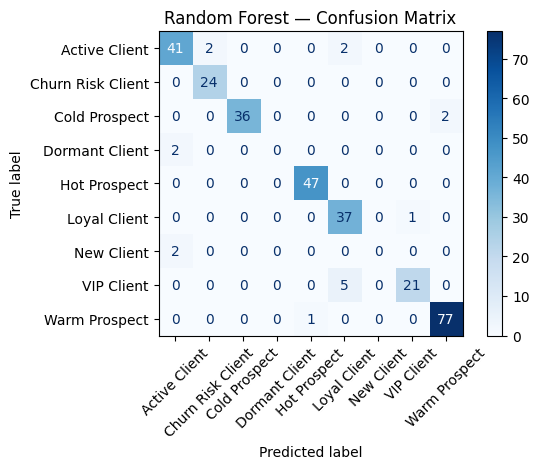

In [11]:
# ============================================================
# Plot 1 — Confusion Matrix for Random Forest
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(X_test)

labels = sorted(y_test.unique())

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(12, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

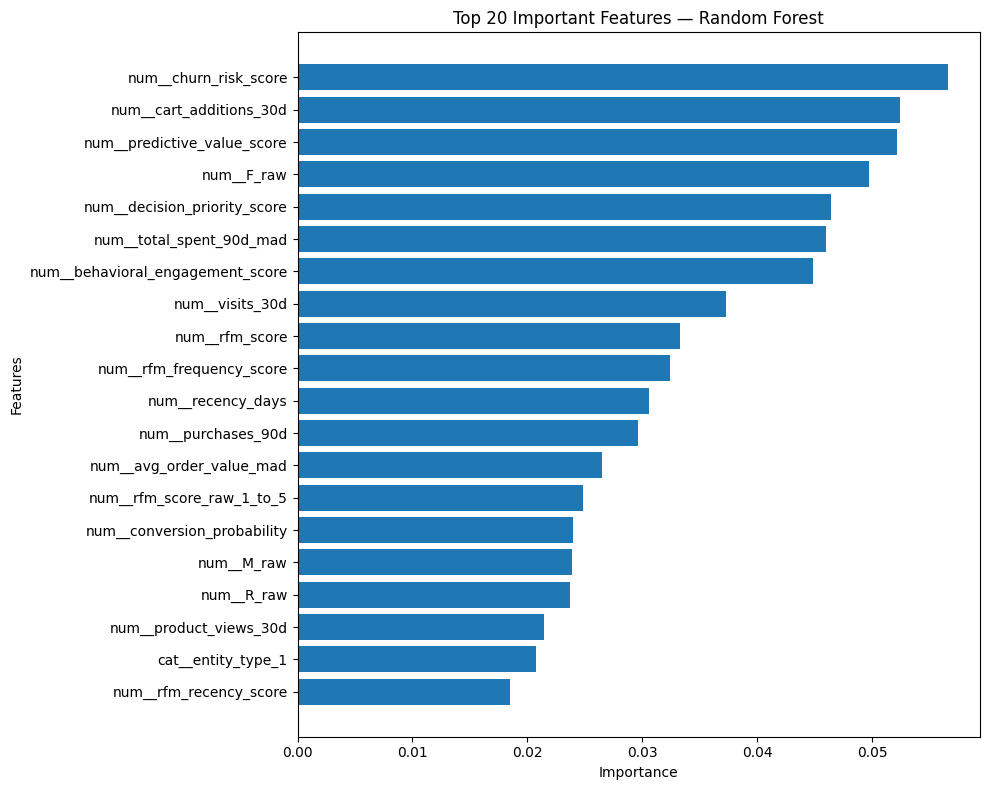

,feature,importance
18,num__churn_risk_score,0.056534
7,num__cart_additions_30d,0.052434
2,num__predictive_value_score,0.052172
23,num__F_raw,0.049737
3,num__decision_priority_score,0.046434
9,num__total_spent_90d_mad,0.045981
1,num__behavioral_engagement_score,0.044853
5,num__visits_30d,0.037257
33,num__rfm_score,0.033268
28,num__rfm_frequency_score,0.032361


In [12]:
# ============================================================
# Plot 2 — Random Forest Feature Importance
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get Random Forest importance values
importances = model.named_steps["classifier"].feature_importances_

feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(by="importance", ascending=False)

# Show top 20
top_features = feature_importance_df.head(20)

plt.figure(figsize=(10, 8))
plt.barh(top_features["feature"], top_features["importance"])
plt.gca().invert_yaxis()
plt.title("Top 20 Important Features — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

feature_importance_df.head(20)

In [13]:
# ============================================================
# Classification Report
# ============================================================

from sklearn.metrics import classification_report, accuracy_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Macro:", f1_score(y_test, y_pred, average="macro"))
print("F1 Weighted:", f1_score(y_test, y_pred, average="weighted"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9433333333333334
F1 Macro: 0.7324320569366753
F1 Weighted: 0.9369015773260811

Classification Report:
                   precision    recall  f1-score   support

    Active Client       0.91      0.91      0.91        45
Churn Risk Client       0.92      1.00      0.96        24
    Cold Prospect       1.00      0.95      0.97        38
   Dormant Client       0.00      0.00      0.00         2
     Hot Prospect       0.98      1.00      0.99        47
     Loyal Client       0.84      0.97      0.90        38
       New Client       0.00      0.00      0.00         2
       VIP Client       0.95      0.81      0.88        26
    Warm Prospect       0.97      0.99      0.98        78

         accuracy                           0.94       300
        macro avg       0.73      0.74      0.73       300
     weighted avg       0.93      0.94      0.94       300



In [14]:
# ============================================================
# Hardcoded examples to test Random Forest model behavior
# ============================================================

import pandas as pd
import numpy as np

# Create a safe base row using X_train structure
# This avoids missing columns errors
base_row = X_train.iloc[0].copy()

def make_example(updates):
    row = base_row.copy()
    for col, value in updates.items():
        if col in row.index:
            row[col] = value
    return row

# ============================================================
# Example 1 — Cold Prospect
# Low engagement, no cart, low conversion probability
# ============================================================

cold_prospect = make_example({
    "entity_type": 0,   # 0 = Prospect, 1 = Client if you encoded it
    "recency_days": 80,
    "visits_30d": 1,
    "product_views_30d": 3,
    "cart_additions_30d": 0,
    "purchases_90d": 0,
    "total_spent_90d_mad": 0,
    "email_open_rate": 0.10,
    "email_click_rate": 0.01,
    "complaint_count_90d": 0,
    "social_mentions_30d": 0,
    "social_sentiment_avg": 0.20,
    "conversion_probability": 0.10,
    "churn_risk_score": 0.00,
    "rfm_score": 0.00,
    "behavioral_engagement_score": 0.10,
    "predictive_value_score": 0.15,
    "decision_priority_score": 0.12
})

# ============================================================
# Example 2 — Warm Prospect
# Some visits, some interest, medium conversion probability
# ============================================================

warm_prospect = make_example({
    "entity_type": 0,
    "recency_days": 25,
    "visits_30d": 8,
    "product_views_30d": 25,
    "cart_additions_30d": 1,
    "purchases_90d": 0,
    "total_spent_90d_mad": 0,
    "email_open_rate": 0.40,
    "email_click_rate": 0.08,
    "complaint_count_90d": 0,
    "social_mentions_30d": 2,
    "social_sentiment_avg": 0.60,
    "conversion_probability": 0.45,
    "churn_risk_score": 0.00,
    "rfm_score": 0.00,
    "behavioral_engagement_score": 0.45,
    "predictive_value_score": 0.40,
    "decision_priority_score": 0.42
})

# ============================================================
# Example 3 — Hot Prospect
# High visits, high product views, cart additions, high conversion
# ============================================================

hot_prospect = make_example({
    "entity_type": 0,
    "recency_days": 5,
    "visits_30d": 25,
    "product_views_30d": 90,
    "cart_additions_30d": 8,
    "purchases_90d": 0,
    "total_spent_90d_mad": 0,
    "email_open_rate": 0.70,
    "email_click_rate": 0.25,
    "complaint_count_90d": 0,
    "social_mentions_30d": 5,
    "social_sentiment_avg": 0.85,
    "conversion_probability": 0.90,
    "churn_risk_score": 0.00,
    "rfm_score": 0.00,
    "behavioral_engagement_score": 0.90,
    "predictive_value_score": 0.85,
    "decision_priority_score": 0.88
})

# ============================================================
# Example 4 — Active Client
# Client with regular purchases and medium/high engagement
# ============================================================

active_client = make_example({
    "entity_type": 1,
    "recency_days": 15,
    "visits_30d": 10,
    "product_views_30d": 35,
    "cart_additions_30d": 3,
    "purchases_90d": 4,
    "total_spent_90d_mad": 2200,
    "avg_order_value_mad": 550,
    "email_open_rate": 0.55,
    "email_click_rate": 0.12,
    "complaint_count_90d": 0,
    "review_score_avg": 4.2,
    "social_mentions_30d": 2,
    "social_sentiment_avg": 0.70,
    "conversion_probability": 1.00,
    "churn_risk_score": 0.20,
    "rfm_score": 0.60,
    "behavioral_engagement_score": 0.55,
    "predictive_value_score": 0.65,
    "decision_priority_score": 0.60
})

# ============================================================
# Example 5 — VIP Client
# Very strong purchase history, high spending, high satisfaction
# ============================================================

vip_client = make_example({
    "entity_type": 1,
    "recency_days": 3,
    "visits_30d": 30,
    "product_views_30d": 100,
    "cart_additions_30d": 12,
    "purchases_90d": 10,
    "total_spent_90d_mad": 12000,
    "avg_order_value_mad": 1200,
    "email_open_rate": 0.80,
    "email_click_rate": 0.30,
    "complaint_count_90d": 0,
    "review_score_avg": 4.8,
    "social_mentions_30d": 8,
    "social_sentiment_avg": 0.90,
    "conversion_probability": 1.00,
    "churn_risk_score": 0.05,
    "rfm_score": 0.95,
    "behavioral_engagement_score": 0.95,
    "predictive_value_score": 0.95,
    "decision_priority_score": 0.92
})

# ============================================================
# Example 6 — Churn Risk Client
# Client with complaints, low engagement, high churn risk
# ============================================================

churn_risk_client = make_example({
    "entity_type": 1,
    "recency_days": 90,
    "visits_30d": 1,
    "product_views_30d": 2,
    "cart_additions_30d": 0,
    "purchases_90d": 1,
    "total_spent_90d_mad": 300,
    "avg_order_value_mad": 300,
    "email_open_rate": 0.08,
    "email_click_rate": 0.01,
    "complaint_count_90d": 4,
    "review_score_avg": 1.8,
    "social_mentions_30d": 3,
    "social_sentiment_avg": 0.10,
    "conversion_probability": 0.20,
    "churn_risk_score": 0.92,
    "rfm_score": 0.20,
    "behavioral_engagement_score": 0.10,
    "predictive_value_score": 0.20,
    "decision_priority_score": 0.75
})

# ============================================================
# Group examples into one DataFrame
# ============================================================

manual_tests = pd.DataFrame([
    cold_prospect,
    warm_prospect,
    hot_prospect,
    active_client,
    vip_client,
    churn_risk_client
])

manual_tests.index = [
    "Cold Prospect Example",
    "Warm Prospect Example",
    "Hot Prospect Example",
    "Active Client Example",
    "VIP Client Example",
    "Churn Risk Client Example"
]

# Predict classes
predictions = model.predict(manual_tests)

results = pd.DataFrame({
    "example": manual_tests.index,
    "predicted_class": predictions
})

# Add recommended actions
actions = []
goals = []

# for pred in predictions:
#     # action, goal = recommend_action(pred, rules)
#     # actions.append(action)
#     # goals.append(goal)

# results["recommended_action"] = actions
# results["business_goal"] = goals

display(results)

,example,predicted_class
0,Cold Prospect Example,Active Client
1,Warm Prospect Example,Active Client
2,Hot Prospect Example,Active Client
3,Active Client Example,Active Client
4,VIP Client Example,VIP Client
5,Churn Risk Client Example,Churn Risk Client


Classes:
0 -> Active Client
1 -> Churn Risk Client
2 -> Cold Prospect
3 -> Dormant Client
4 -> Hot Prospect
5 -> Loyal Client
6 -> New Client
7 -> VIP Client
8 -> Warm Prospect

Training model: Logistic Regression

Training model: Random Forest

Training model: Extra Trees

Training model: Gradient Boosting

Training model: Hist Gradient Boosting

Training model: MLP Neural Network

Training model: XGBoost

Training model: LightGBM

Training model: CatBoost


,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,training_time_seconds
8,CatBoost,0.973333,0.864430,0.818728,0.832205,0.969649,7.533427
3,Gradient Boosting,0.966667,0.757481,0.758445,0.757573,0.963712,6.998940
6,XGBoost,0.956667,0.740947,0.752082,0.746254,0.950551,3.012527
7,LightGBM,0.950000,0.738741,0.746384,0.741761,0.944116,2.537969
4,Hist Gradient Boosting,0.946667,0.737263,0.744809,0.740581,0.940849,5.755490
1,Random Forest,0.936667,0.727850,0.739186,0.732536,0.930469,0.463387
2,Extra Trees,0.876667,0.688265,0.708318,0.697194,0.870288,0.356479
5,MLP Neural Network,0.883333,0.686473,0.696890,0.690643,0.877351,1.716863
0,Logistic Regression,0.866667,0.685834,0.684463,0.684165,0.871482,0.097801



Best model: CatBoost


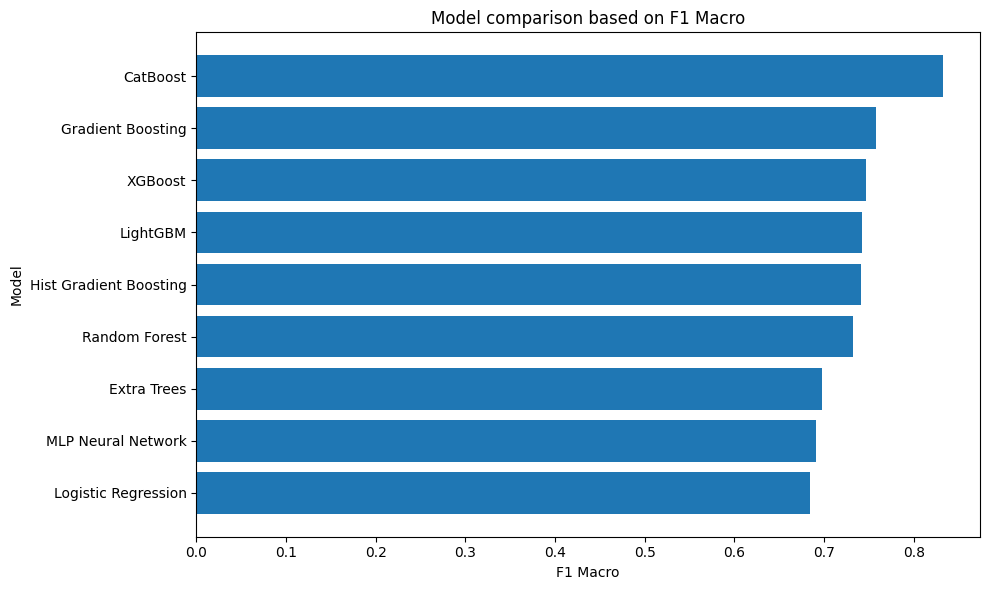


Classification report for best model:
                   precision    recall  f1-score   support

    Active Client       0.93      0.93      0.93        45
Churn Risk Client       0.96      1.00      0.98        24
    Cold Prospect       1.00      1.00      1.00        38
   Dormant Client       1.00      0.50      0.67         2
     Hot Prospect       1.00      1.00      1.00        47
     Loyal Client       0.93      0.97      0.95        38
       New Client       0.00      0.00      0.00         2
       VIP Client       0.96      0.96      0.96        26
    Warm Prospect       1.00      1.00      1.00        78

         accuracy                           0.97       300
        macro avg       0.86      0.82      0.83       300
     weighted avg       0.97      0.97      0.97       300



<Figure size 1200x800 with 0 Axes>

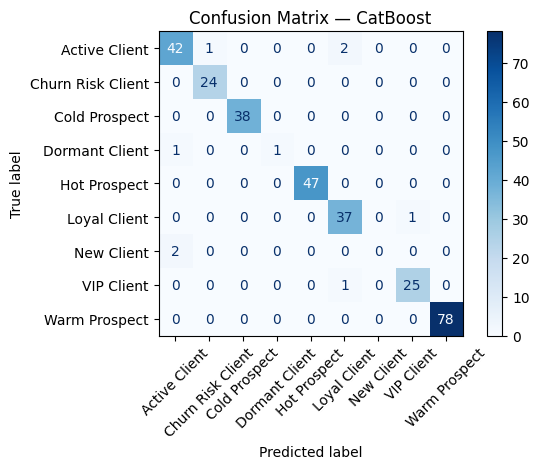

In [15]:
# ============================================================
# Multi-model comparison for OSMOS dynamic classification
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier

# ------------------------------------------------------------
# 1. Encode target labels
# ------------------------------------------------------------

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

class_names = label_encoder.classes_

print("Classes:")
for i, cls in enumerate(class_names):
    print(i, "->", cls)

# ------------------------------------------------------------
# 2. Define models
# ------------------------------------------------------------

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=4,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=4,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=300,
        random_state=42
    ),

    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        max_iter=500,
        random_state=42
    )
}

# ------------------------------------------------------------
# 3. Optional advanced models
# ------------------------------------------------------------

try:
    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )

except ImportError:
    print("XGBoost is not installed. To install it: pip install xgboost")


try:
    from lightgbm import LGBMClassifier

    models["LightGBM"] = LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=-1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

except ImportError:
    print("LightGBM is not installed. To install it: pip install lightgbm")


try:
    from catboost import CatBoostClassifier

    models["CatBoost"] = CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        loss_function="MultiClass",
        verbose=False,
        random_state=42
    )

except ImportError:
    print("CatBoost is not installed. To install it: pip install catboost")


# ------------------------------------------------------------
# 4. Train and evaluate all models
# ------------------------------------------------------------

results = []
trained_models = {}

for model_name, classifier in models.items():
    print(f"\nTraining model: {model_name}")

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    start_time = time.time()

    model.fit(X_train, y_train_encoded)

    training_time = time.time() - start_time

    y_pred_encoded = model.predict(X_test)

    accuracy = accuracy_score(y_test_encoded, y_pred_encoded)
    precision_macro = precision_score(y_test_encoded, y_pred_encoded, average="macro", zero_division=0)
    recall_macro = recall_score(y_test_encoded, y_pred_encoded, average="macro", zero_division=0)
    f1_macro = f1_score(y_test_encoded, y_pred_encoded, average="macro")
    f1_weighted = f1_score(y_test_encoded, y_pred_encoded, average="weighted")

    results.append({
        "model": model_name,
        "accuracy": accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted,
        "training_time_seconds": training_time
    })

    trained_models[model_name] = model

# ------------------------------------------------------------
# 5. Results table
# ------------------------------------------------------------

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="f1_macro", ascending=False)

display(results_df)

best_model_name = results_df.iloc[0]["model"]
best_model = trained_models[best_model_name]

print("\nBest model:", best_model_name)

# ------------------------------------------------------------
# 6. Plot model comparison
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.barh(results_df["model"], results_df["f1_macro"])
plt.gca().invert_yaxis()
plt.xlabel("F1 Macro")
plt.ylabel("Model")
plt.title("Model comparison based on F1 Macro")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Detailed report for best model
# ------------------------------------------------------------

best_pred_encoded = best_model.predict(X_test)

print("\nClassification report for best model:")
print(classification_report(
    y_test_encoded,
    best_pred_encoded,
    target_names=class_names
))

# ------------------------------------------------------------
# 8. Confusion matrix for best model
# ------------------------------------------------------------

cm = confusion_matrix(y_test_encoded, best_pred_encoded)

plt.figure(figsize=(12, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Save best model artifact for Streamlit interface
# ============================================================

import joblib

model_artifact = {
    "model": best_model,
    "label_encoder": label_encoder,
    "feature_columns": list(X_train.columns),
    "best_model_name": best_model_name,
    "selection_metric": "f1_macro",
    "results": results_df
}

joblib.dump(model_artifact, "osmos_best_model_artifact.pkl")

print("Best model saved:", best_model_name)
print("Artifact saved as: osmos_best_model_artifact.pkl")

Best model saved: CatBoost
Artifact saved as: osmos_best_model_artifact.pkl


: 